# Amazon Fine Food Reviews — Sentiment Prediction from `Summary`

**Goal.** Use the review *Summary* text to predict sentiment: **positive** if `Score > 3`, otherwise **negative** (binary classification).

**Pipeline**
1. Import & prepare data, create the target variable
2. Text cleaning (lower case, punctuation, stop words, stemming)
3. Feature engineering: unigram, bigram, TF-IDF (+ Word2Vec bonus)
4. Models: Logistic Regression and Random Forest
5. Evaluation: ROC / AUC, Precision, Recall, F1
6. Feature importance
7. Save & restore the model

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from preprocess import clean_text, STOP_WORDS, NEGATIONS

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn import metrics

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

os.makedirs("images", exist_ok=True)
def save(name):
    plt.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")

## 1. Import and prepare data

In [2]:
df = pd.read_csv("Reviews.csv")
df.columns = ["Id", "ProductId", "UserId", "ProfileName", "VotesHelpful",
              "VotesTotal", "Score", "Time", "Summary", "Text"]
print(df.shape)
df.head()

(568454, 10)


,Id,ProductId,UserId,ProfileName,VotesHelpful,VotesTotal,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


**Data quality checks**

* A few rows have an empty `Summary` – they cannot be used as input, so they are dropped.
* The dataset is known to contain the *same* review posted under several product variants (same user, same time, same text). Keeping them would leak identical rows into both train and test and inflate the scores, so they are de-duplicated.

In [3]:
print("Missing Summary:", df["Summary"].isna().sum())
before = len(df)
df = df.dropna(subset=["Summary"])
df = df.drop_duplicates(subset=["UserId", "ProfileName", "Time", "Text"])
print(f"Rows: {before:,} -> {len(df):,}  (removed {before - len(df):,})")

Missing Summary: 27
Rows: 568,454 -> 393,930  (removed 174,524)


**Target variable** – `Sentiment = 1` (positive) if `Score > 3`, else `0` (negative, includes score 3 as required by the problem statement).

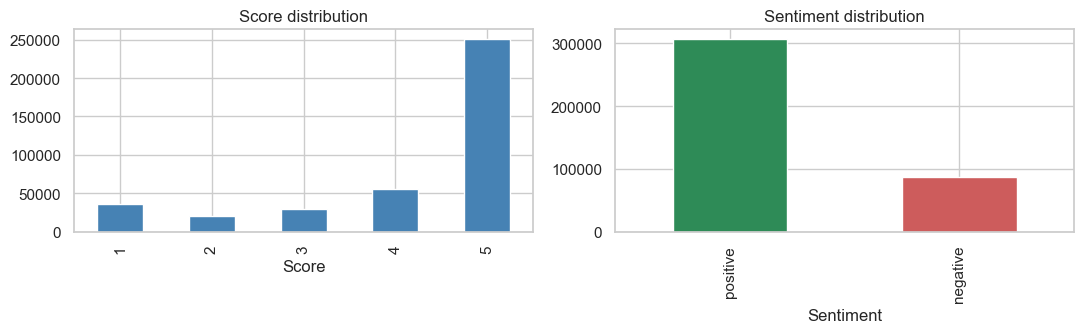

Sentiment
positive    0.779468
negative    0.220532
Name: proportion, dtype: float64


In [4]:
df["Sentiment"] = (df["Score"] > 3).astype(int)
df = df[["Score", "Summary", "Sentiment"]].reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["Score"].value_counts().sort_index().plot.bar(ax=ax[0], color="steelblue")
ax[0].set_title("Score distribution")
df["Sentiment"].map({1: "positive", 0: "negative"}).value_counts().plot.bar(ax=ax[1], color=["seagreen", "indianred"])
ax[1].set_title("Sentiment distribution")
plt.tight_layout(); save("class_distribution"); plt.show()

print(df["Sentiment"].value_counts(normalize=True).rename({1: "positive", 0: "negative"}))

The classes are imbalanced (~78% positive). A model that always says *positive* would already get ~78% accuracy, so **accuracy alone is not a good metric**; we focus on AUC and on precision / recall / F1 of the *negative* class.

## 2. Data cleaning

* lower case
* remove punctuation / non-letters
* remove stop words — **but keep negations** (`not`, `no`, `nor`, `don't` …). NLTK's default list contains them, and dropping them would turn *"not good"* into *"good"*, which destroys exactly the signal we need.
* Porter stemming (`tasty -> tasti`)

In [5]:
# clean_text lives in preprocess.py so that training and inference (predict.py) use exactly the same steps
print("negations kept:", sorted(NEGATIONS)[:10], "...")
print("example:", clean_text("This is NOT the tastiest snack I've had... don't buy!"))

t = time.time()
df["Clean"] = df["Summary"].map(clean_text)
print(f"cleaned in {time.time() - t:.1f}s")
df = df[df["Clean"].str.len() > 0].reset_index(drop=True)   # summaries that were only stop words / symbols
df.sample(8, random_state=1)[["Summary", "Clean", "Sentiment"]]

negations kept: ['aren', "aren't", 'couldn', "couldn't", 'didn', "didn't", 'doesn', "doesn't", 'don', "don't"] ...
example: not tastiest snack not buy
cleaned in 0.7s


,Summary,Clean,Sentiment
336410,Good for Keurig Hot Chocolate,good keurig hot chocol,1
95587,"Not sprouting yet, but close",not sprout yet close,1
19393,Nothing like the picture!!,noth like pictur,0
16944,Best sugar alternative,best sugar altern,1
333831,Good stuff!,good stuff,1
275810,Not as good as expected...,not good expect,0
235188,BETTER IF PURCHASED FROM YOUR LOCAL DELI,better purchas local deli,0
312293,heathier alternative to ramen cup o' soup.,heathier altern ramen cup soup,1


### Train / test split (80 / 20, stratified)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["Clean"], df["Sentiment"], test_size=0.2,
    stratify=df["Sentiment"], random_state=RANDOM_STATE)
print(f"train: {len(X_train):,}   test: {len(X_test):,}")

train: 314,452   test: 78,614


## 3. Feature engineering + 4. Models

Each feature extractor is wrapped in a `Pipeline` with its classifier, so the vectorizer is fit on the **training set only** and the whole thing can be saved as one object.

| name | features |
|---|---|
| Unigram | `CountVectorizer(ngram_range=(1,1))` |
| Bigram | `CountVectorizer(ngram_range=(1,2))` – single words + word pairs, captures *"not good"* |
| TF-IDF | `TfidfVectorizer(ngram_range=(1,2))` – down-weights words that appear everywhere |

`min_df=5` drops very rare tokens (typos, noise).

In [7]:
def lr():
    return LogisticRegression(C=1.0, max_iter=1000, solver="liblinear")

pipelines = {
    "LR + Unigram": Pipeline([("vec", CountVectorizer(ngram_range=(1, 1), min_df=5)), ("clf", lr())]),
    "LR + Bigram":  Pipeline([("vec", CountVectorizer(ngram_range=(1, 2), min_df=5)), ("clf", lr())]),
    "LR + TF-IDF":  Pipeline([("vec", TfidfVectorizer(ngram_range=(1, 2), min_df=5, sublinear_tf=True)), ("clf", lr())]),
}

results, probas = {}, {}
for name, pipe in pipelines.items():
    t = time.time()
    pipe.fit(X_train, y_train)
    probas[name] = pipe.predict_proba(X_test)[:, 1]
    print(f"{name:<14} vocab={len(pipe.named_steps['vec'].vocabulary_):>7,}  fit {time.time() - t:5.1f}s")

LR + Unigram   vocab=  6,500  fit   1.3s
LR + Bigram    vocab= 23,549  fit   3.5s
LR + TF-IDF    vocab= 23,549  fit   1.9s


**Random Forest.** Trees on hundreds of thousands of sparse n-gram columns are slow, so the RF uses the 5,000 most frequent TF-IDF uni/bi-grams. Everything else (data, split) is identical.

In [8]:
pipelines["RF + TF-IDF"] = Pipeline([
    ("vec", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=5000, sublinear_tf=True)),
    ("clf", RandomForestClassifier(n_estimators=100, min_samples_leaf=2,
                                   n_jobs=-1, random_state=RANDOM_STATE)),
])
t = time.time()
pipelines["RF + TF-IDF"].fit(X_train, y_train)
probas["RF + TF-IDF"] = pipelines["RF + TF-IDF"].predict_proba(X_test)[:, 1]
print(f"RF fit {time.time() - t:.1f}s")

RF fit 16.3s


### Bonus: Word2Vec embedding

Train a Word2Vec model on the training summaries and represent each summary as the **average of its word vectors**, then feed that 100-dim dense vector into Logistic Regression.

In [9]:
from gensim.models import Word2Vec

train_tokens = [s.split() for s in X_train]
test_tokens  = [s.split() for s in X_test]
w2v = Word2Vec(train_tokens, vector_size=100, window=5, min_count=5, workers=8, seed=RANDOM_STATE, epochs=10)

def doc_vec(tokens):
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

Xw_train = np.vstack([doc_vec(t) for t in train_tokens])
Xw_test  = np.vstack([doc_vec(t) for t in test_tokens])
lr_w2v = LogisticRegression(max_iter=1000).fit(Xw_train, y_train)
probas["LR + Word2Vec"] = lr_w2v.predict_proba(Xw_test)[:, 1]

print("most similar to 'delici':", [w for w, _ in w2v.wv.most_similar("delici", topn=6)])
print("most similar to 'aw':    ", [w for w, _ in w2v.wv.most_similar("aw", topn=6)])

most similar to 'delici': ['tasti', 'delish', 'yummi', 'tastey', 'delic', 'incred']
most similar to 'aw':     ['terribl', 'horribl', 'nasti', 'horrid', 'funni', 'strang']


## 5. Model evaluation

In [10]:
rows = []
for name, p in probas.items():
    pred = (p >= 0.5).astype(int)
    rows.append({
        "model": name,
        "ROC AUC": metrics.roc_auc_score(y_test, p),
        "Accuracy": metrics.accuracy_score(y_test, pred),
        "Precision (neg)": metrics.precision_score(y_test, pred, pos_label=0),
        "Recall (neg)": metrics.recall_score(y_test, pred, pos_label=0),
        "F1 (neg)": metrics.f1_score(y_test, pred, pos_label=0),
        "F1 (pos)": metrics.f1_score(y_test, pred, pos_label=1),
        "Macro F1": metrics.f1_score(y_test, pred, average="macro"),
    })
scores = pd.DataFrame(rows).set_index("model").sort_values("ROC AUC", ascending=False)
scores.style.format("{:.4f}").highlight_max(color="#c6efce")

,ROC AUC,Accuracy,Precision (neg),Recall (neg),F1 (neg),F1 (pos),Macro F1
model,,,,,,,
LR + TF-IDF,0.9313,0.8950,0.8351,0.6510,0.7316,0.9347,0.8332
LR + Bigram,0.9288,0.8946,0.8270,0.6586,0.7332,0.9343,0.8338
RF + TF-IDF,0.9209,0.8870,0.7998,0.6486,0.7163,0.9295,0.8229
LR + Unigram,0.9149,0.8808,0.8027,0.6071,0.6913,0.9261,0.8087
LR + Word2Vec,0.8895,0.8564,0.7542,0.5147,0.6119,0.9119,0.7619


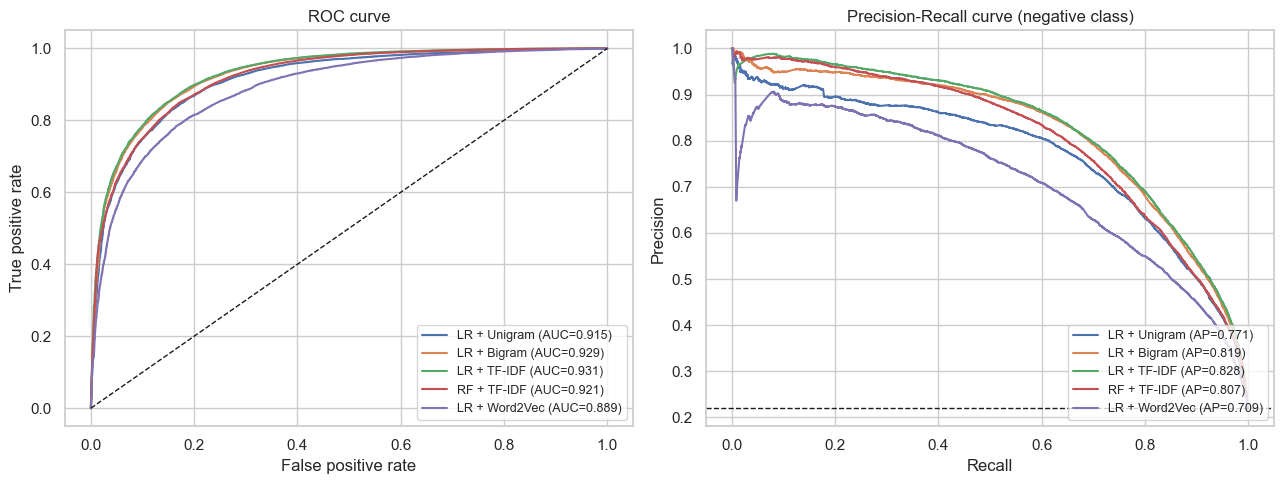

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in probas.items():
    fpr, tpr, _ = metrics.roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={metrics.roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = metrics.precision_recall_curve(y_test, 1 - p, pos_label=0)
    ax[1].plot(rec, prec, label=f"{name} (AP={metrics.average_precision_score(1 - y_test, 1 - p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
ax[1].axhline((y_test == 0).mean(), color="k", ls="--", lw=1)
ax[1].set(title="Precision-Recall curve (negative class)", xlabel="Recall", ylabel="Precision")
for a in ax: a.legend(loc="lower right", fontsize=9)
plt.tight_layout(); save("roc_pr_curves"); plt.show()

Best model: LR + TF-IDF 

              precision    recall  f1-score   support

    negative     0.8351    0.6510    0.7316     17290
    positive     0.9073    0.9637    0.9347     61324

    accuracy                         0.8950     78614
   macro avg     0.8712    0.8074    0.8332     78614
weighted avg     0.8915    0.8950    0.8900     78614



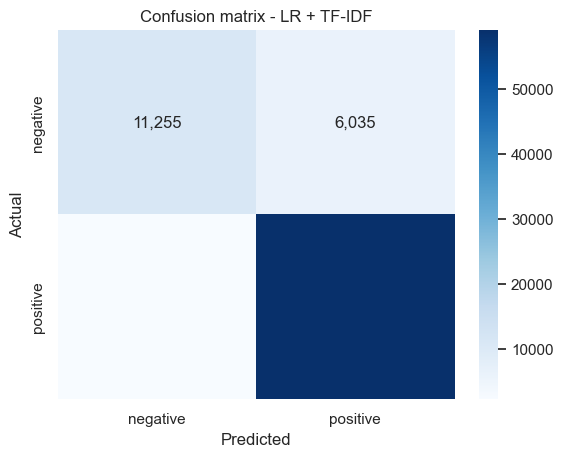

In [12]:
best_name = scores.index[0]
best = pipelines[best_name]
pred = best.predict(X_test)
print("Best model:", best_name, "\n")
print(metrics.classification_report(y_test, pred, target_names=["negative", "positive"], digits=4))

cm = metrics.confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues",
            xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"Confusion matrix - {best_name}"); save("confusion_matrix"); plt.show()

**Choosing the threshold.** With the default 0.5 cut-off the model is biased toward the majority (positive) class. If the business goal is to *catch unhappy customers*, we care more about recall of the negative class. Sweeping the threshold shows the trade-off; we pick the one that maximises negative-class F1.

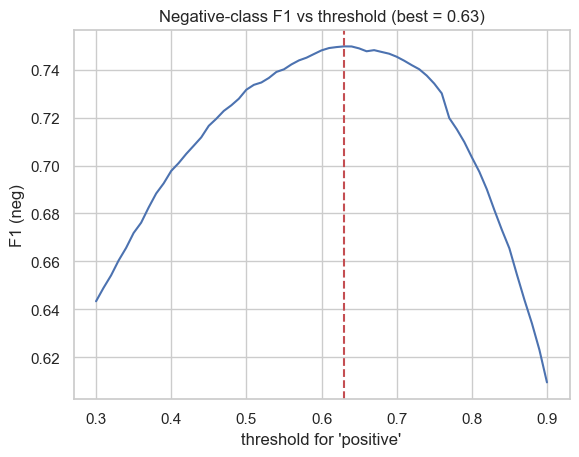

Threshold 0.63:
              precision    recall  f1-score   support

    negative     0.7648    0.7351    0.7497     17290
    positive     0.9261    0.9363    0.9312     61324

    accuracy                         0.8920     78614
   macro avg     0.8455    0.8357    0.8404     78614
weighted avg     0.8907    0.8920    0.8913     78614



In [13]:
p_best = probas[best_name]
ths = np.linspace(0.3, 0.9, 61)
f1s = [metrics.f1_score(y_test, (p_best >= th).astype(int), pos_label=0) for th in ths]
best_th = ths[int(np.argmax(f1s))]
plt.plot(ths, f1s); plt.axvline(best_th, ls="--", color="r")
plt.title(f"Negative-class F1 vs threshold (best = {best_th:.2f})"); plt.xlabel("threshold for 'positive'"); plt.ylabel("F1 (neg)"); plt.show()

print(f"Threshold {best_th:.2f}:")
print(metrics.classification_report(y_test, (p_best >= best_th).astype(int),
                                    target_names=["negative", "positive"], digits=4))

## 6. Feature importance

* **Logistic Regression** – the coefficient of each n-gram tells both *strength* and *direction*: large positive → pushes toward *positive*, large negative → toward *negative*.
* **Random Forest** – `feature_importances_` (mean decrease in impurity) gives strength only, not direction.

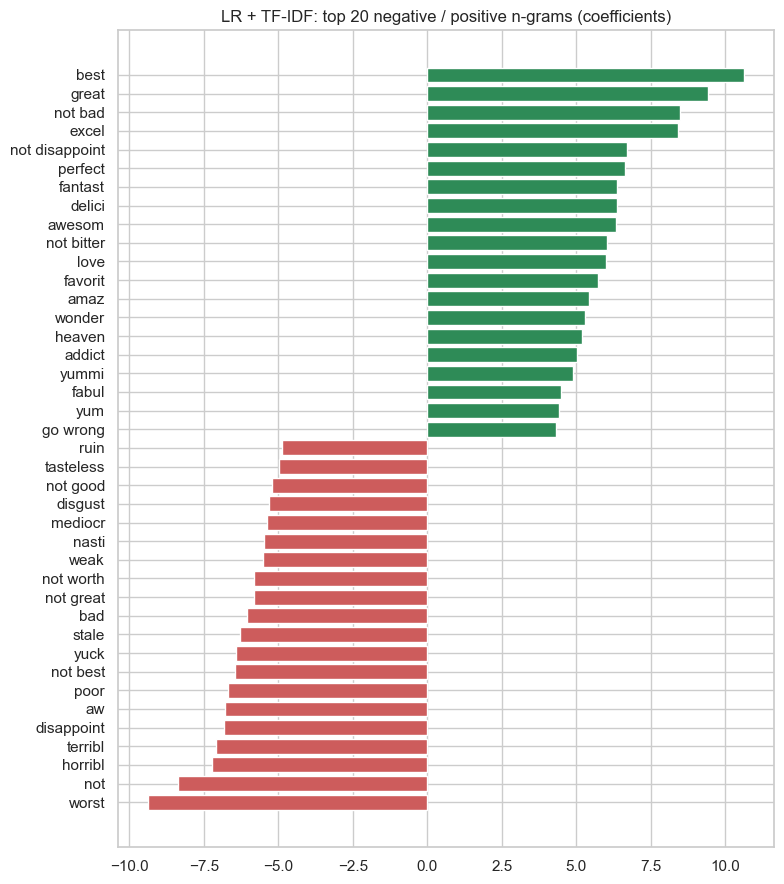

In [14]:
vec = pipelines["LR + TF-IDF"].named_steps["vec"]
coef = pipelines["LR + TF-IDF"].named_steps["clf"].coef_[0]
feat = np.array(vec.get_feature_names_out())
order = np.argsort(coef)
top = np.r_[order[:20], order[-20:]]

plt.figure(figsize=(8, 9))
plt.barh(feat[top], coef[top], color=["indianred"] * 20 + ["seagreen"] * 20)
plt.title("LR + TF-IDF: top 20 negative / positive n-grams (coefficients)")
plt.tight_layout(); save("lr_coefficients"); plt.show()

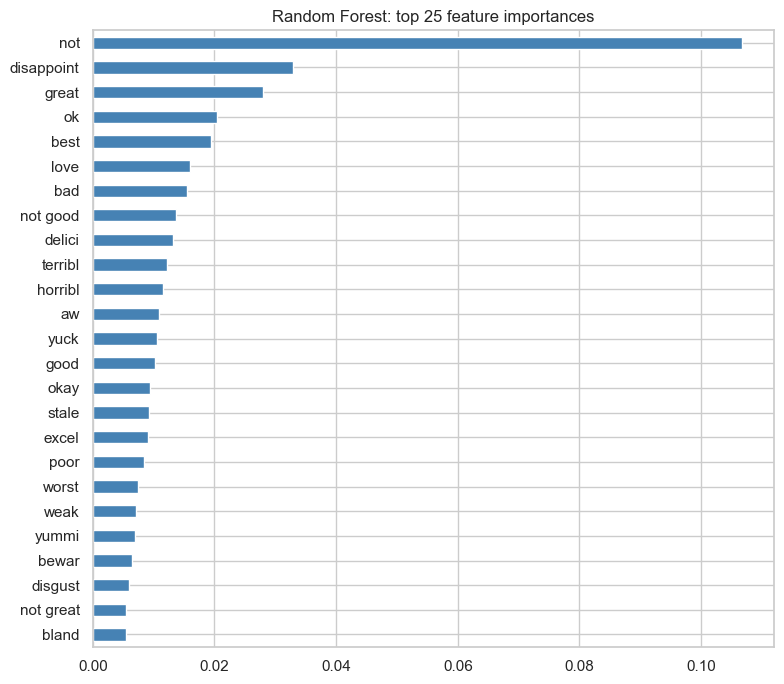

In [15]:
rf_vec = pipelines["RF + TF-IDF"].named_steps["vec"]
rf = pipelines["RF + TF-IDF"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=rf_vec.get_feature_names_out()).nlargest(25)

plt.figure(figsize=(8, 7))
imp[::-1].plot.barh(color="steelblue")
plt.title("Random Forest: top 25 feature importances")
plt.tight_layout(); save("rf_importances"); plt.show()

## 7. Save & restore the model

In production we do **not** retrain before every prediction. The fitted pipeline (vectorizer vocabulary + IDF weights + model coefficients) is serialised once with `joblib`; the serving code just loads it and calls `predict`. The cleaning function must be applied the same way at inference time, so it is bundled with the threshold in the saved file.

In [16]:
artifact = {"pipeline": best, "threshold": float(best_th), "model_name": best_name}
joblib.dump(artifact, "sentiment_model.joblib", compress=3)
print("saved sentiment_model.joblib  (command line: python predict.py 'your review')")

# ---- later / in another process ----
loaded = joblib.load("sentiment_model.joblib")

def predict_sentiment(texts):   # same logic as predict.py
    cleaned = [clean_text(t) for t in texts]
    p = loaded["pipeline"].predict_proba(cleaned)[:, 1]
    return pd.DataFrame({"text": texts, "P(positive)": p.round(3),
                         "prediction": np.where(p >= loaded["threshold"], "positive", "negative")})

predict_sentiment([
    "Absolutely delicious, will buy again!",
    "Not good at all",
    "Not bad",
    "Stale and overpriced",
    "My dog loves it",
    "Arrived broken, very disappointed",
])

saved sentiment_model.joblib  (command line: python predict.py 'your review')


,text,P(positive),prediction
0,"Absolutely delicious, will buy again!",0.973,positive
1,Not good at all,0.004,negative
2,Not bad,0.601,negative
3,Stale and overpriced,0.004,negative
4,My dog loves it,0.977,positive
5,"Arrived broken, very disappointed",0.011,negative


## Conclusions

* **Short summaries carry a strong sentiment signal.** TF-IDF + Logistic Regression reaches a test ROC AUC of **0.931** and accuracy of 89.5%. Random Forest scores 0.921, unigram-only LR 0.915 and averaged Word2Vec about 0.89.
* **Bigrams matter.** Adding word pairs lets the model learn negation: *"not bad"*, *"not disappoint"* and *"not bitter"* are among the strongest **positive** features, while *"not good"*, *"not worth"* and *"not great"* are strongly negative. This only works because negations were kept out of the stop-word list.
* **TF-IDF + Logistic Regression is the best trade-off**: best AUC, trains in seconds, and its coefficients are directly interpretable. Random Forest is slower, needs a restricted vocabulary, and does not beat it on sparse text. Averaged Word2Vec loses word order and negation, so it scores lowest.
* **Class imbalance.** About 78% of reviews are positive, so the default 0.5 threshold under-detects negative reviews. Raising the threshold to 0.63 increases negative-class recall from 0.65 to 0.74 and F1 from 0.732 to 0.750. The right threshold depends on the business cost of missing an unhappy customer versus raising a false alarm.
* **Most predictive stems.** Positive: *best, great, excel, perfect, fantast, delici, awesom, love*. Negative: *worst, not, horribl, terribl, disappoint, aw(ful), poor, stale*.
* **Limitation.** The unigram *not* is itself a strong negative signal, so a two-word summary like *"Not bad"* still scores only 0.60 and falls below the tuned threshold. A model on the full review `Text`, or a contextual model, would handle such cases better.
* **Deployment.** The fitted pipeline is saved once with `joblib` and reloaded for prediction (`predict.py`), so no retraining is needed until the data drifts.
